## Problem 3: Statement

a) For the example of the one-dimensional Ising model with free boundary conditions determine the partition function by exact enumeration of all states. To this end write a computer program for $N = 5, 10$ and $20$ spins ($2^N = 2^{20} \approx 10^6$ states) at $\beta=1$ (resp. $T = J/k_B$). Use the simplest possible implementation ($5-20$ nested do-loops). Check the result for $N = 5$ ($2^5 = 32$ states) through explicit counting "by hand". Finally compare with the analytical result of problem 1.

b) How can the code be modified with minimal changes such that the exact result can be easily obtained for all temperatures?

c) With another small modification one can obtain exact results for all temperatures and all magnetic fields? How? There will be another homework dealing with this problem.

## Problem 3: Solution

(a)

From Homework 1, Problem 1 we know that for an 1D Ising model with free boundaries the partition function can be written as:

$$
Z=\sum_{s_1=\pm1}\cdots\sum_{s_N=\pm1}e^{\frac{J}{k_B T}(s_1s_2+s_2s_3+\cdots+s_{N-2}s_{N-1}+s_{N-1}s_N)} \tag{1}
$$

We can algorithmically determine this partition function by the method of exact enumaration of all the states. 

We do so by using nested `for` loops, where we loop over the spin states $[-1,1]$ for each particle in the 1D Ising chain. The number of nested for loops depends on $N$, so for $N=5$, we have 5 loops, for $N=10$, we have 10 loops and so on. The energy is defined in the inner-most nested loop; as given by the exponent of the exponential in eq. (1). Before performing the calculations, we predefine the variables and define the exponential function.

In [14]:
import math

def exp(x):
    return math.exp(x)

spins=[-1,1]

Z_5=0
E_5=0
print("EXACT ENUMERATION RESULTS:")


## N=5
for s1 in spins:
    for s2 in spins:
        for s3 in spins:
            for s4 in spins:
                for s5 in spins:
                    E_5=-1*(s1*s2 + s2*s3+s3*s4+s4*s5)
                    Z_5+=exp(-E_5)

print("For N=5, Z =", Z_5)

Z_10=0
E_10=0
for s1 in spins:
    for s2 in spins:
        for s3 in spins:
            for s4 in spins:
                for s5 in spins:
                    for s6 in spins:
                        for s7 in spins:
                            for s8 in spins:
                                for s9 in spins:
                                    for s10 in spins:
                                        E_10=-1*(s1*s2 + s2*s3+s3*s4+s4*s5+s5*s6+s6*s7+s7*s8+s8*s9+s9*s10)
                                        Z_10+=exp(-E_10)
print("For N=10, Z =", Z_10)

Z_20=0
E_20=0
for s1 in spins:
    for s2 in spins:
        for s3 in spins:
            for s4 in spins:
                for s5 in spins:
                    for s6 in spins:
                        for s7 in spins:
                            for s8 in spins:
                                for s9 in spins:
                                    for s10 in spins:
                                        for s11 in spins:
                                            for s12 in spins:
                                                for s13 in spins:
                                                    for s14 in spins:
                                                        for s15 in spins:
                                                            for s16 in spins:
                                                                for s17 in spins:
                                                                    for s18 in spins:
                                                                        for s19 in spins:
                                                                            for s20 in spins:
                                                                                E_20=-1*(s1*s2 + s2*s3+s3*s4+s4*s5+s5*s6+s6*s7+s7*s8+s8*s9+s9*s10+s10*s11+s11*s12+s12*s13+s13*s14+s14*s15+s15*s16+s16*s17+s17*s18+s18*s19+s19*s20)
                                                                                Z_20+=exp(-E_20)

print("For N=20, Z =", Z_20)


EXACT ENUMERATION RESULTS:
For N=5, Z = 181.42806240140408
For N=10, Z = 50792.26102565571
For N=20, Z = 3980922408.678104


Derived Homework 1, the analytical expression for the partition function is the following

$$
\boxed{Z=2^N\left[\cosh\left(\frac{J}{k_B T}\right)\right]^{N-1}} \tag{2}
$$

Using that we can compute analytically the values of $Z$ for $N=5,10,20$.

In [15]:
def Z(N):
    return 2**N*(math.cosh(1))**(N-1)

print("ANALYTICAL RESULTS:")
print("For N=5, Z =", Z(5))
print("For N=10, Z =", Z(10))
print("For N=20, Z =", Z(20))

ANALYTICAL RESULTS:
For N=5, Z = 181.42806240140402
For N=10, Z = 50792.26102565565
For N=20, Z = 3980922408.72465


In [16]:
d_5=Z(5)-Z_5
d_10=Z(10)-Z_10
d_20=Z(20)-Z_20

print("DIFFERENCES BETWEEN EXACT ENUMERATION AND ANALYTICAL RESULTS:")
print("For N=5, difference =", d_5)
print("For N=10, difference =", d_10)
print("For N=20, difference =", d_20)

DIFFERENCES BETWEEN EXACT ENUMERATION AND ANALYTICAL RESULTS:
For N=5, difference = -5.684341886080802e-14
For N=10, difference = -5.820766091346741e-11
For N=20, difference = 0.046545982360839844


Comparing the two results we see that they are almost identical. By subtracting them we find that for $N=5, 10$ differences are extremely small, but for $N=20$ difference is significantly larger in magnitude, but still small relative to the actual numerical value of $Z$. I assume the discrepancy arises due to numerical implementations of $\cosh$, because the value is most certainly rounded to a digit that furthermore introduces a certain error into the analytical result.

(b)

The code can be modified by adding a simple temperature factor (instead of 1) in the energy term  so that the exact result can be easily obtained for all temperatures. See below:

In [17]:
import math

def exp(x):
    return math.exp(x)

spins=[-1,1]

Z_5=0
E_5=0
T=1.0
J=1.0
k_b=1.0
print("EXACT ENUMERATION RESULTS:")


## N=5
for s1 in spins:
    for s2 in spins:
        for s3 in spins:
            for s4 in spins:
                for s5 in spins:
                    E_5=-J/(k_b*T)*(s1*s2 + s2*s3+s3*s4+s4*s5)
                    Z_5+=exp(-E_5)

print("For N=5, Z =", Z_5)

Z_10=0
E_10=0
for s1 in spins:
    for s2 in spins:
        for s3 in spins:
            for s4 in spins:
                for s5 in spins:
                    for s6 in spins:
                        for s7 in spins:
                            for s8 in spins:
                                for s9 in spins:
                                    for s10 in spins:
                                        E_10=-J/(k_b*T)*(s1*s2 + s2*s3+s3*s4+s4*s5+s5*s6+s6*s7+s7*s8+s8*s9+s9*s10)
                                        Z_10+=exp(-E_10)
print("For N=10, Z =", Z_10)

Z_20=0
E_20=0
for s1 in spins:
    for s2 in spins:
        for s3 in spins:
            for s4 in spins:
                for s5 in spins:
                    for s6 in spins:
                        for s7 in spins:
                            for s8 in spins:
                                for s9 in spins:
                                    for s10 in spins:
                                        for s11 in spins:
                                            for s12 in spins:
                                                for s13 in spins:
                                                    for s14 in spins:
                                                        for s15 in spins:
                                                            for s16 in spins:
                                                                for s17 in spins:
                                                                    for s18 in spins:
                                                                        for s19 in spins:
                                                                            for s20 in spins:
                                                                                E_20=-J/(k_b*T)*(s1*s2 + s2*s3+s3*s4+s4*s5+s5*s6+s6*s7+s7*s8+s8*s9+s9*s10+s10*s11+s11*s12+s12*s13+s13*s14+s14*s15+s15*s16+s16*s17+s17*s18+s18*s19+s19*s20)
                                                                                Z_20+=exp(-E_20)

print("For N=20, Z =", Z_20)


EXACT ENUMERATION RESULTS:
For N=5, Z = 181.42806240140408
For N=10, Z = 50792.26102565571
For N=20, Z = 3980922408.678104


(c)

By adding another term into the energy function, we can include a magnetic field term. The final energy expression is therefore then given by eq. (3)

$$
E=-J \sum_{i=1}^{N-1}s_i s_{i+1} + B\sum_{i=1}^{N}s_i \tag{3}
$$

This together with the previous temperature accounting change allows us to calculate the partition function for any temperature and magnetic field.

## Problem 4: Statement

The free energy per spin, $\beta f_N \equiv -\frac{1}{N}\ln(Z_N)$, of the one-dimensional Ising model of a chain with $N$ spins reads in the thermodynamic limit $N \to \infty$ independent of the boundary conditions:

$$
\beta f_{\infty} \equiv -\lim_{N \to \infty} \frac{1}{N}\ln(Z_N)=-\ln(2)-\ln(\cosh(\beta))
$$

**Note: This equation in the problem statement assumes $J=1$, hence in my solutions I will too assume $J=1$**

a) Calculate the finite-size correction $\beta f_N - \beta f_{\infty}$ for i) free and ii) periodic boundary conditions.

b) Plot both corrections as a function of $N$ for $\beta = 1, 2, 10$ in the range $[1, 10]$. To be able to disentangle the different curves, you may set the y-range to, e.g., $[0, 2]$. For a comparison of the two boundary conditions it is useful to plot $|\beta f_N - \beta f_{\infty}|$ (why?).

c) Repeat b) with a logarithmic y-scale in the $N$-range $[1, 100]$. Why does the curve for $\beta = 1$ and periodic boundary conditions appear as a straight line in the limit of large $N$? What does that mean mathematically? How can one understand the analogous curves for $\beta = 2, 10$?

## Problem 4: Solution

(a)

In this task we wish to calculate the finite-size correction $\beta f_N - \beta f_{\infty}$ for both free and periodic boundary conditions. Let us start with the free boundary condition.

(i) Free boundary conditions

Recalling from Homework 1, the partition function of a 1D Ising model with free boundary conditions is

$$
\boxed{Z_N=2^N\left[\cosh(\beta)\right]^{N-1}} \tag{4}
$$

From the problem statement, the free energy per spin is

$$
\beta f_N \equiv -\frac{1}{N}\ln(Z_N) \tag{5}
$$

Plugging eq. (4) into eq. (5)

$$
\begin{aligned}
\beta f_N &= -\frac{1}{N}\ln\left(2^N\left[\cosh(\beta)\right]^{N-1}\right)\\
&= -\frac{1}{N}\Big(N\ln(2)+(N-1)\ln(\cosh(\beta))\Big)\\
&= -\ln(2)-\frac{N-1}{N}\ln(\cosh(\beta))
\end{aligned} \tag{6}
$$

Again, from the problem statement we know

$$
\beta f_{\infty} \equiv -\lim_{N \to \infty} \frac{1}{N}\ln(Z_N)=-\ln(2)-\ln(\cosh(\beta)) \tag{7}
$$

Therefore, we can calculate $\beta f_N - \beta f_{\infty}$ by subtracting eq. (7) from eq. (6):

$$
\begin{aligned}
\beta f_N - \beta f_{\infty} &= -\ln(2)-\frac{N-1}{N}\ln(\cosh(\beta))+\ln(2)+\ln(\cosh(\beta))\\
&= \left(1-\frac{N-1}{N}\right)\ln(\cosh(\beta))\\
&= \boxed{\frac{1}{N}\ln(\cosh(\beta))}
\end{aligned} \tag{8}
$$

(ii) Periodic boundary conditions

During the lecture we derived the partition function of the 1D Ising model with periodic boundary conditions using the transfer matrix method. The derived expression, with $J=1$, is

$$
\begin{aligned}
Z_N &= 2^N\cosh^N(\beta)\left[1+\tanh^N(\beta)\right]\\
&= 2^N\cosh^N(\beta)+2^N\sinh^N(\beta)
\end{aligned} \tag{9}
$$

Using eq. (5) as a blueprint, the free energy per spin is

$$
\begin{aligned}
\beta f_N &= -\frac{1}{N}\ln\left(2^N\cosh^N(\beta)\left[1+\tanh^N(\beta)\right]\right)\\
&= -\frac{1}{N}\Big(\ln\left(2^N\cosh^N(\beta)\right)+\ln\left(1+\tanh^N(\beta)\right)\Big)\\
&= -\frac{1}{N}\Big(N\ln(2)+N\ln(\cosh(\beta))+\ln\left(1+\tanh^N(\beta)\right)\Big)\\
&= -\ln(2)-\ln(\cosh(\beta))-\frac{1}{N}\ln\left(1+\tanh^N(\beta)\right)
\end{aligned} \tag{10}
$$

Then we calculate $\beta f_N - \beta f_{\infty}$ by subtracting eq. (7) from eq. (10):

$$
\begin{aligned}
\beta f_N - \beta f_{\infty} &= -\ln(2)-\ln(\cosh(\beta))-\frac{1}{N}\ln\left(1+\tanh^N(\beta)\right)+\ln(2)+\ln(\cosh(\beta))\\
&= \boxed{-\frac{1}{N}\ln\left(1+\tanh^N(\beta)\right)}
\end{aligned} \tag{11}
$$



(b)

In this part of the problem we plot both the absolute values of both corrections a function of $N$ for $\beta = 1, 2, 10$ in the range $[1, 10]$. It is useful to plot the absolute value $|\beta f_N - \beta f_{\infty}|$ because the periodic boundary correction function is always general negative. In order to disentangle the different curves, we set the y-range to $[0, 2]$. 




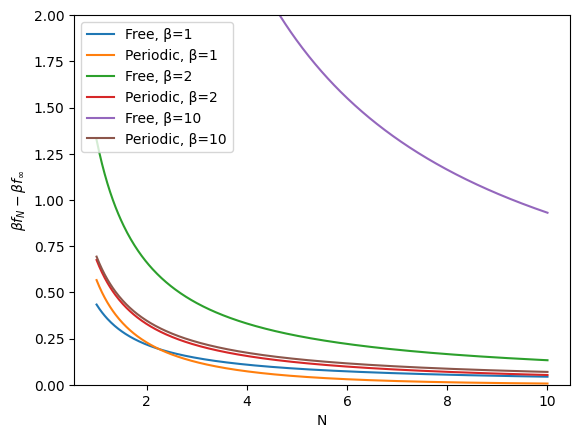

In [5]:
import numpy as np
from matplotlib import pyplot as plt

J = 1.0
k_b = 1.0

beta_values = [1,2,10]

N = np.linspace(1, 10, 500)

def corr_free(N,beta):
   return abs(1/N*np.log(np.cosh(beta)))

def corr_periodic(N,beta):
   return abs(-1/N*np.log(1+np.tanh(beta)**N))


for beta in beta_values:
    plt.plot(N, corr_free(N, beta), label=f"Free, β={beta}")
    plt.plot(N, corr_periodic(N, beta), label=f"Periodic, β={beta}")

plt.ylim(0,2)
plt.xlabel("N")
plt.ylabel(r"$\beta f_N - \beta f_{\infty}$")
plt.legend()
plt.show()


Figure 1. Dependence of $|\beta f_N - \beta f_{\infty}|$ on $N$, for free and periodic boundary conditions and $\beta=1,2,10$

(c)

In this part of the problem we repeat (b) with a logarithmic y-scale in the range $N \in [1, 100]$. 

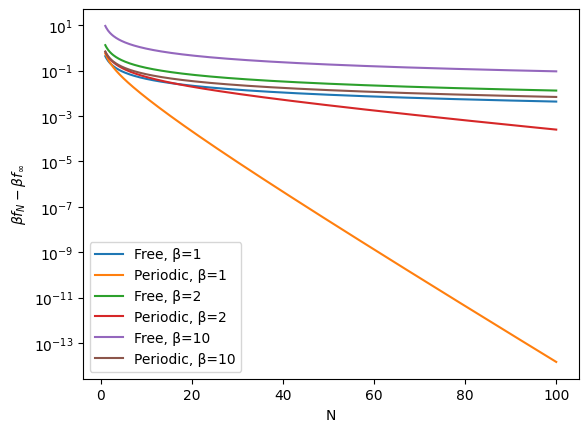

In [7]:
import numpy as np
from matplotlib import pyplot as plt

J = 1.0
k_b = 1.0

beta_values = [1,2,10]

N = np.linspace(1, 100, 500)

def corr_free(N,beta):
   return abs(1/N*np.log(np.cosh(beta)))

def corr_periodic(N,beta):
   return abs(-1/N*np.log(1+np.tanh(beta)**N))


for beta in beta_values:
    plt.plot(N, corr_free(N, beta), label=f"Free, β={beta}")
    plt.plot(N, corr_periodic(N, beta), label=f"Periodic, β={beta}")

plt.yscale("log")
plt.xlabel("N")
plt.ylabel(r"$\beta f_N - \beta f_{\infty}$")
plt.legend()
plt.show()


Figure 2. Dependence of $|\beta f_N - \beta f_{\infty}|$ on $N$ on a logarithmic scale, for free and periodic boundary conditions and $\beta=1,2,10$

As we can see on Fig. 2, for periodic boundary conditions with $\beta = 1$ the curve decreases linearly for large $N$. Since the y-axis is logarithmic, this means that on a normal scale the correction decays exponentially with $N$.

This can also be seen analytically. Recalling eq. (11), the finite-size correction for periodic boundary conditions is

$$
\beta f_N - \beta f_{\infty} = -\frac{1}{N}\ln\left(1+\tanh^N(\beta)\right) \tag{12}
$$

Since $\tanh(1) < 1$, for large $N$ we have $\tanh^N(1) \to 0$. For small $\tanh^N(1)$ we can therefore use the Taylor expansion $\ln(1+y) \approx y$ for $|y| \ll 1$, which gives

$$
\ln\left(1+\tanh^N(1)\right) \approx \tanh^N(1) \tag{13}
$$

Plugging eq. (13) into eq. (12), for large $N$ we obtain

$$
\boxed{|\beta f_N - \beta f_{\infty}| \approx \frac{1}{N}\tanh^N(1)} \tag{14}
$$

which is exactly the exponential behaviour observed on Fig. 2. To see why it appears as a straight line, we take the logarithm of eq. (14):

$$
\begin{aligned}
\ln|\beta f_N - \beta f_{\infty}| &\approx \ln\left(\frac{1}{N}\tanh^N(1)\right)\\
&= N\ln(\tanh(1)) - \ln(N)
\end{aligned} \tag{15}
$$

where $\ln(\tanh(1)) \approx -0.2723$. For large $N$ the term $N\ln(\tanh(1))$ dominates, since it grows linearly in $N$, while $\ln(N)$ grows only logarithmically. This allows us to neglect the $\ln(N)$ term, so the curve on the logarithmic scale is (approximately) a straight line with slope

$$
\boxed{\ln(\tanh(1)) \approx -0.2723} \tag{16}
$$

Mathematically this means that the finite-size correction decays exponentially with $N$, since $\tanh^N(1) = e^{N\ln(\tanh(1))}$ with $\ln(\tanh(1)) < 0$.